# Phase 02 - Credit Card Fraud Detection
# KIC-BSCCSAI-251.P-018
## Option A - Baseline Implementation


**Reference paper:** Kennedy et al. (2024), *Synthesizing class labels for highly imbalanced credit card fraud detection data*.

The aim of this practical work is to train baseline models on the dataset used in the paper and compare their results with the authors' results. Logistic Regression and Random Forest use the real labels. Isolation Forest and an autoencoder are also tested, followed by a smaller experiment using generated labels.

The dataset file, `creditcard.csv`, should be in the same folder as this notebook.


## Step 1 - Importing libraries
The random seed is set to 42 for repeatable results.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import average_precision_score

SEED = 42          # fixed seed so I can get the same result again
np.random.seed(SEED)

Matplotlib is building the font cache; this may take a moment.


## Step 2 - Loading and checking the dataset
The dataset contains 284,807 transactions and 31 columns. The target is `Class`, where 0 represents a genuine transaction and 1 represents fraud.


In [3]:
df = pd.read_csv("creditcard.csv")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Class distribution
There are 492 fraud cases, which is about 0.173% of the dataset. This large class imbalance makes accuracy alone unsuitable for evaluating fraud detection.


In [4]:
print(df["Class"].value_counts())
print("fraud percent:", round(df["Class"].mean() * 100, 4))

Class
0    284315
1       492
Name: count, dtype: int64
fraud percent: 0.1727


### Missing values and duplicates
The checks show no missing values and 1,081 exact duplicate rows. Duplicates are retained in this experiment. This is a limitation because identical records may appear in both training and testing. The paper does not clearly report how duplicates were handled.


In [5]:
print("missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())

missing values: 0
duplicate rows: 1081


## Step 3 - Feature analysis and input selection
The summary shows that Amount has a different range from the PCA features. Scaling is therefore included in the Logistic Regression pipeline and the autoencoder experiments.


In [23]:
df[["V1", "V2", "V28", "Amount"]].describe().round(2)

,V1,V2,V28,Amount
count,284807.00,284807.00,284807.00,284807.00
mean,0.00,0.00,-0.00,88.35
std,1.96,1.65,0.33,250.12
min,-56.41,-72.72,-15.43,0.00
25%,-0.92,-0.60,-0.05,5.60
50%,0.02,0.07,0.01,22.00
75%,1.32,0.80,0.08,77.16
max,2.45,22.06,33.85,25691.16


### Input features and target
Time is removed to follow the paper's input selection. X contains Amount and V1-V28, giving 29 features. The real labels are stored separately in y. Removing Time is a comparison choice, not evidence that the feature has no value.


In [6]:
df = df.drop(columns=["Time"])
X = df.drop(columns=["Class"])
y = df["Class"].values
print(X.shape, y.sum())

(284807, 29) 492


## Step 4 - Cross-validation setup
Stratified five-fold cross-validation is used to keep similar fraud proportions in each fold. Each model trains on four folds and is evaluated on the remaining fold.

This experiment uses one repeat, giving five scores per model. The paper uses ten repeats, giving 50 scores per model and P setting.


In [7]:
N_REPEATS = 1
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED)
folds = list(cv.split(X, y))
print("number of folds:", len(folds))

number of folds: 5


### Evaluation function
The function returns the average precision score for each fold. The code labels these scores AUPRC, but `average_precision_score` calculates AP. AP and trapezoidal PR area are different calculations, so comparisons with the paper's reported AUPRC need care.


In [8]:
def cv_auprc(model, X, y, folds):
    scores = []
    for tr, te in folds:
        model.fit(X.iloc[tr], y[tr])
        prob = model.predict_proba(X.iloc[te])[:, 1]
        scores.append(average_precision_score(y[te], prob))
    return np.array(scores)

## Step 5 - Logistic Regression baseline
Logistic Regression is trained using the real labels. StandardScaler is fitted inside the pipeline using only the training fold. Balanced class weights give more importance to the rare fraud class.


In [9]:
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
lr_scores = cv_auprc(lr, X, y, folds)
print("LR AUPRC per fold:", lr_scores.round(4))
print("LR mean AUPRC:", lr_scores.mean().round(4))

LR AUPRC per fold: [0.7088 0.7247 0.7286 0.7775 0.7105]
LR mean AUPRC: 0.73


## Step 6 - Random Forest baseline
Random Forest uses 100 trees and the real labels. The maximum depth is unrestricted. The authors use a maximum depth of 4 and train on generated labels, which makes this a different baseline setup.


In [10]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
rf_scores = cv_auprc(rf, X, y, folds)
print("RF AUPRC per fold:", rf_scores.round(4))
print("RF mean AUPRC:", rf_scores.mean().round(4))

RF AUPRC per fold: [0.8357 0.8835 0.8618 0.847  0.8166]
RF mean AUPRC: 0.8489


## Step 7 - Isolation Forest baseline
Isolation Forest learns without training labels. Its scores are reversed so that a larger value indicates a more unusual transaction.

Contamination is set using the full dataset's known fraud rate. The paper describes an expert-provided expected rate instead. AP is calculated from `score_samples`, whose ranking does not depend on the contamination threshold.


In [11]:
if_scores = []
for tr, te in folds:
    iso = IsolationForest(contamination=y.mean(), random_state=SEED, n_jobs=-1)
    iso.fit(X.iloc[tr])
    anomaly = -iso.score_samples(X.iloc[te])
    if_scores.append(average_precision_score(y[te], anomaly))
if_scores = np.array(if_scores)
print("IF mean AUPRC:", if_scores.mean().round(4), "(paper says 0.2414)")

IF mean AUPRC: 0.1472 (paper says 0.2414)


## Step 8 - Autoencoder baseline
MLPRegressor is used to reconstruct the inputs. The reconstruction error is the mean squared difference between the input and its predicted copy.

The model has hidden layers of 100, 50, 50 and 100 neurons, with ReLU hidden activations and a linear output. It uses a learning rate of 0.001, up to 20 epochs and validation-based early stopping with patience 5.

This differs from the paper's Keras model, which uses tanh decoder hidden layers, ReLU output, a learning rate of 0.0001 and up to 250 epochs. The authors monitor training loss with patience 25. My autoencoder is a simplified baseline rather than an exact reproduction.


In [12]:
def train_autoencoder(X_train_scaled):
    ae = MLPRegressor(hidden_layer_sizes=(100, 50, 50, 100),
                      activation="relu", solver="adam",
                      learning_rate_init=0.001, batch_size=256,
                      max_iter=20, early_stopping=True,
                      validation_fraction=0.2, n_iter_no_change=5,
                      random_state=SEED)
    ae.fit(X_train_scaled, X_train_scaled)
    return ae

def recon_error(ae, X_scaled):
    return ((X_scaled - ae.predict(X_scaled)) ** 2).mean(axis=1)

### Direct evaluation of reconstruction error
The scaler and autoencoder are fitted separately within each training fold. Reconstruction errors on the test fold are used directly as fraud scores and evaluated against the real labels.


In [13]:
ae_only_scores = []
for tr, te in folds:
    sc = StandardScaler().fit(X.iloc[tr])
    ae = train_autoencoder(sc.transform(X.iloc[tr]))
    err_test = recon_error(ae, sc.transform(X.iloc[te]))
    ae_only_scores.append(average_precision_score(y[te], err_test))
ae_only_scores = np.array(ae_only_scores)
print("AE-error-only mean AUPRC:", ae_only_scores.mean().round(4))

AE-error-only mean AUPRC: 0.5459


## Step 9 - Generating labels
The scaler and autoencoder are fitted on the whole dataset in this part. Transactions are ranked by reconstruction error. The top P transactions receive label 1, while the rest receive label 0. These labels indicate possible fraud, not confirmed fraud.

Since later test inputs influence this preparation, the synthetic-label evaluation is less reliable for completely unseen transactions. This also differs from the training-only autoencoder baseline in Step 8.


In [ ]:
scaler_all = StandardScaler().fit(X)
X_all_scaled = scaler_all.transform(X)
ae_full = train_autoencoder(X_all_scaled)
err_all = recon_error(ae_full, X_all_scaled)
order = np.argsort(-err_all)      # highest error first
print("done, first 5 errors:", err_all[order[:5]].round(2))

done, first 5 errors: [0.37 0.34 0.25 0.23 0.22]


In [15]:
def make_labels(P):
    labels = np.zeros(len(err_all), dtype=int)
    labels[order[:P]] = 1
    return labels

### Checking generated label quality
Generated labels are compared with the real answers for analysis. Label precision measures how many generated positive labels are correct. Label recall measures how much real fraud is included. This full-data check is descriptive and is not an independent validation of the best P value.


In [16]:
rows = []
for P in [500, 1000, 1500, 1700, 2500]:
    lab = make_labels(P)
    true_fraud = y[lab == 1].sum()
    rows.append({"P": P,
                 "real frauds inside": int(true_fraud),
                 "label precision": round(true_fraud / P, 4),
                 "label recall": round(true_fraud / y.sum(), 4)})
pd.DataFrame(rows)

,P,real frauds inside,label precision,label recall
0,500,225,0.4500,0.4573
1,1000,331,0.3310,0.6728
2,1500,378,0.2520,0.7683
3,1700,386,0.2271,0.7846
4,2500,401,0.1604,0.8150


## Step 10 - Training with generated labels
Decision Tree, Logistic Regression and Random Forest are trained on generated labels and evaluated against real labels. Five P settings are tested: 500, 1,000, 1,500, 1,700 and 2,500. The paper tests six classifiers and 21 P settings, so this is a smaller experiment.


In [17]:
def cv_synthetic(model, P):
    lab = make_labels(P)
    scores = []
    for tr, te in folds:
        model.fit(X.iloc[tr], lab[tr])
        prob = model.predict_proba(X.iloc[te])[:, 1]
        scores.append(average_precision_score(y[te], prob))   # real labels here
    return np.mean(scores)

In [18]:
P_LIST = [500, 1000, 1500, 1700, 2500]
models = {
    "DT": lambda: DecisionTreeClassifier(random_state=SEED),
    "LR": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "RF": lambda: RandomForestClassifier(n_estimators=100, max_depth=4, n_jobs=-1, random_state=SEED),
}
my_results = {name: [] for name in models}
for name, make in models.items():
    for P in P_LIST:
        my_results[name].append(cv_synthetic(make(), P))
        print(name, P, round(my_results[name][-1], 4))

DT 500 0.2037
DT 1000 0.2197
DT 1500 0.1674
DT 1700 0.1706
DT 2500 0.1276
LR 500 0.4711
LR 1000 0.5675
LR 1500 0.6046
LR 1700 0.613
LR 2500 0.6378
RF 500 0.5303
RF 1000 0.5679
RF 1500 0.581
RF 1700 0.5742
RF 2500 0.5741


## Step 11 - Comparison with the paper
The reference scores are taken from Tables 4 and 5 of the paper. The graphs compare my scores with the corresponding published scores. The dashed line shows the paper's Isolation Forest result.

Differences in preprocessing, models, evaluation repetitions and AP/AUPRC calculations mean these are descriptive comparisons, not proof of a better method.


In [19]:
paper = {
    "DT": [0.2935, 0.3181, 0.3714, 0.3774, 0.3813],
    "LR": [0.2301, 0.2793, 0.3226, 0.3256, 0.3191],
    "RF": [0.3394, 0.3529, 0.3596, 0.3597, 0.3009],
}
table = pd.DataFrame({"P": P_LIST})
for name in models:
    table[name + " (mine)"] = np.round(my_results[name], 4)
    table[name + " (paper)"] = paper[name]
table

,P,DT (mine),DT (paper),LR (mine),LR (paper),RF (mine),RF (paper)
0,500,0.2037,0.2935,0.4711,0.2301,0.5303,0.3394
1,1000,0.2197,0.3181,0.5675,0.2793,0.5679,0.3529
2,1500,0.1674,0.3714,0.6046,0.3226,0.5810,0.3596
3,1700,0.1706,0.3774,0.6130,0.3256,0.5742,0.3597
4,2500,0.1276,0.3813,0.6378,0.3191,0.5741,0.3009


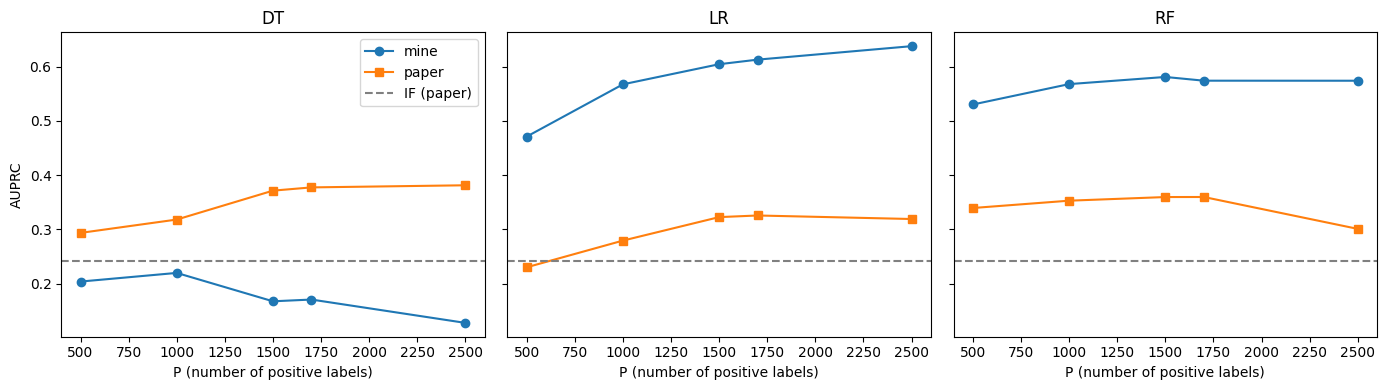

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, models):
    ax.plot(P_LIST, my_results[name], marker="o", label="mine")
    ax.plot(P_LIST, paper[name], marker="s", label="paper")
    ax.axhline(0.2414, color="gray", linestyle="--", label="IF (paper)")
    ax.set_title(name)
    ax.set_xlabel("P (number of positive labels)")
axes[0].set_ylabel("AUPRC")
axes[0].legend()
plt.tight_layout()
plt.show()

### Overall baseline comparison
The table combines the baseline results with published reference values. My supervised baselines use real training labels, while the authors' classifiers use generated labels. This gives my models additional information during training.


In [21]:
final = pd.DataFrame({
    "Model": ["Logistic Regression (real labels)",
              "Random Forest (real labels)",
              "Isolation Forest (mine)",
              "Isolation Forest (paper)",
              "Autoencoder error only (mine)",
              "Paper's best (NB, P=2500)"],
    "AUPRC": [lr_scores.mean(), rf_scores.mean(), if_scores.mean(),
              0.2414, ae_only_scores.mean(), 0.3893],
}).round(4)
final

,Model,AUPRC
0,Logistic Regression (real labels),0.7300
1,Random Forest (real labels),0.8489
2,Isolation Forest (mine),0.1472
3,Isolation Forest (paper),0.2414
4,Autoencoder error only (mine),0.5459
5,"Paper's best (NB, P=2500)",0.3893


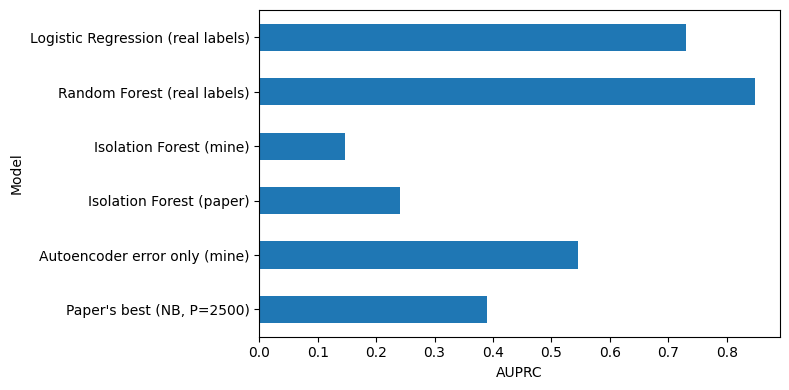

In [22]:
final.plot.barh(x="Model", y="AUPRC", legend=False, figsize=(8, 4))
plt.xlabel("AUPRC")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 12 - Results and discussion
Random Forest achieved the highest AP among the real-label baselines, at 0.8489. Logistic Regression achieved 0.7300. Both scores are numerically above the paper's best reported AUPRC of 0.3893, but the training labels and evaluation procedures differ. This does not prove that my method is better at solving the authors' label-cost problem.

Isolation Forest achieved 0.1472, compared with the paper's reported value of 0.2414. The autoencoder-only baseline achieved 0.5459. Its score cannot be directly compared with the generated-label branch to measure the benefit of adding a classifier, because their autoencoders were fitted differently.

Increasing P had different effects on the classifiers. Logistic Regression increased from 0.4711 at P=500 to 0.6378 at P=2,500. Random Forest reached its highest score of 0.5810 at P=1,500 and then fell slightly. Decision Tree reached 0.2197 at P=1,000 and fell to 0.1276 at P=2,500. More generated labels therefore did not always improve performance.

At P=500, 225 generated positives were real fraud cases. At P=2,500, this increased to 401, but label precision fell from 45% to 16.04%. The larger setting captured more fraud while also labelling more genuine payments as fraud.

### Limitations
- Exact duplicates remain and may appear across folds.
- Only one five-fold repetition is used, compared with ten in the paper.
- The autoencoder architecture and training settings differ from the authors' settings.
- The generated-label branch fits preparation on all inputs before cross-validation.
- My AP scores and the paper's reported AUPRC may use different calculations.
- The best P is selected from the evaluated settings. No independent final test or statistical significance test supports that selection.

### Conclusion
The experiment provides baseline results for credit-card fraud detection and explores the use of generated labels. The real-label models performed well numerically, while the generated-label results depended on both the model and P. A closer comparison would require matching the authors' settings and using consistent, training-only preparation.

### References
Kennedy et al. (2024). *Synthesizing class labels for highly imbalanced credit card fraud detection data*. Journal of Big Data, 11, 38. https://doi.org/10.1186/s40537-024-00897-7

Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
